## TP5 - Name

In [1]:
## imports
import csv
import numpy as np
import matplotlib.pyplot as plt

### PART 1 - Monday, November 14, 2022

In [2]:
with open('X.dat', newline='') as f:
    reader = csv.reader(f, quoting=csv.QUOTE_NONNUMERIC)
    X_dat = list(reader)
with open('Y.dat', newline='') as f:
    reader = csv.reader(f, quoting=csv.QUOTE_NONNUMERIC)
    Y_dat = list(reader)

## 2D array of shape (200, 400), each row (image) contains the 400 grey values of each image
X = np.array(X_dat).reshape(200, 400)
## list of 200 labels, label for each image, 1 if image is '2' and 0 if image is '3'
y_k = [y[0] for y in Y_dat]

(200, 400)
label y = 1.0


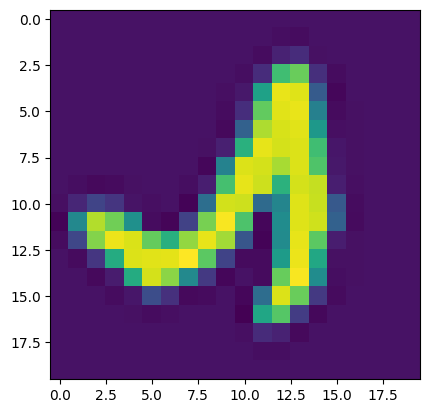

In [3]:
print(X.shape)
plt.imshow(X[0].reshape(20,-1));
print(f'label y = {y_k[0]}')

In [4]:
## NOTE : HELPER FUNCTION, IF NEEDED
# Checks if all elements of a list are equal
def checkEqual(lst):
    '''
    checks if all elements of a list are equal
    (by checking if the count of the first element is equal to the list length)

    Parameters:
    -----------
    lst : list of x elements

    Returns:
    --------
    True if all x elements of the list are equal, and False otherwise
    '''
    return lst.count(lst[0]) == len(lst)

In [5]:
# Sigmoidal function
def fun_sigmoid(x):
    '''
    compute sigmoid of value x

    Parameters:
    -----------
    x : scalar value

    Returns:
    --------
    sigmoid(x)
    '''
    return 1 / (1 + np.exp(-x))


# Calculate h-w1-w2
def h12(pso, X):
    '''
    calculate state of activation of the output layer of neurons (list of 200 values, a value for each image)

    Parameters:
    -----------
    pso : position vector of one particle
    X : 2D array of shape (200, 400), each row (image) contains the 400 grey values of each image

    Returns:
    --------
    h : list of 200 values representing the state of activation of the output layer of neurons
    '''
    # w2 matrix, (1, 26) of last 26 elements of pso
    w2 = pso[-26:]
    w2 = w2.reshape(1, 26)

    # w1 matrix (25, 401) of first 25*401 elements of pso
    w1 = pso[:25 * 401]
    w1 = w1.reshape(25, 401)


    # results' list containing h value for each image
    results = []
    # for every image x
    for x in X:
        # get image (& copy !!)
        x = x.copy()
        # add 1 at 0-position
        x = np.insert(x, 0, 1)
        # reshape
        x = x.reshape(401, 1) # useless
        # calculate c = matrix multiplication of weight matrix 1 and image vector(with 1 at position 0)
        c1 = w1 @ x
        # apply sigmoidal function on elements of c
        z = fun_sigmoid(c1)
        # add 1 at 0-position
        z = np.insert(z, 0, 1)
        # reshape
        z = z.reshape(26, 1)
        # calculate matrix multiplication of weight matrix 2 and vector z(with 1 at position 0), answer is scalar
        c2 = w2 @ z
        # apply sigmoidal fucntion on answer
        h = fun_sigmoid(c2)
        # results, append all h12 for all images
        results.append(h.item())

    return results


# Calculate overall fitness J
def calculate_J(h, y_k):
    '''
    calculate overall fitness J (equation #5 in TP PDF)

    Parameters:
    -----------
    h : list of 200 values representing the state of activation of the output layer of neurons
    y_k : list of 200 labels '1' or '0', for each image

    Returns:
    --------
    fitness_J : overall fitness, mean of all J for each image
    '''
    h = np.asarray(h).reshape(-1)
    y_k = np.asarray(y_k).reshape(-1)
    
    fitness_J = np.mean((y_k - h)**2)
    
    return fitness_J

# prediction accuracy of images
def pred_acc(h, X, y_k):
    '''
    calculate the prediction accuracy (%) by comparing prediction & true labels
    y_p (predicted label) = 1 if h>=0.5 & 0 otherwise

    Parameters:
    -----------
    h : list of 200 values representing the state of activation of the output layer of neurons (to be used for best h12)
    X : 2D array of shape (200, 400), each row (image) contains the 400 grey values of each image
    y_k : list of 200 labels '1' or '0', for each image

    Returns:
    --------
    acc : prediction accuracy
    '''
    h = np.asarray(h).reshape(-1)
    y_k = np.asarray(y_k).reshape(-1)

    # get predicted labels
    y_pred = (h >= 0.5).astype(int)
    # get prediction accuracy (%)
    acc = np.mean(y_pred == y_k) * 100
    
    return acc


In [ ]:
# Algorithm, and training the network
def pso_NN(X, y_k, N, vmax_coeff, m):
    '''
    perfom PSO algorithm with NN training

    Parameters:
    -----------
    X : 2D array of shape (200, 400), each row (image) contains the 400 grey values of each image
    y_k : list of 200 labels '1' or '0', for each image
    N : number of particles
    vmax_coeff : velocity cutoff coefficient (% of coordinates range, for eg: vmax_coeff=0.1 means vmax=0.1*(xmax_coordinate-xmin_coordinate))
    m : number of neighbors used to compute the "global best"

    Returns:
    --------
    J_g : global best fitness
    b_g : global best position
    h_g : global best state activation of output neurons (needed later for prediction)
    J_global : list of all global best positions (for each iteration, needed to plot later on)
    '''
    ## Fixed Parameters
    # cognitive & social parameters
    c1 = c2 = 2
    # inertia constant
    w = 0.9
    # number of coefficients 'n' of weight matrices 1 & 2, combined (go back to h12 function for a reminder if needed)
    n = 25 * 401 + 26
    ## Variate Parameters
    # coordinates' range
    c_min, c_max = -1, 1
    #c_min, c_max = -0.5, 0.5
    c_range = [c_min, c_max]
    # velocity threshold vmax = vmax_coeff*(c_max - c_min)
    vmax = vmax_coeff*(c_max - c_min)


    ## NOTE : STOPPING CONDITION
    # choose one of these two stopping conditions: 
    # 1. number of iterations, tmax=?
    tmax = 300
    # 2. last _ fitness values are equal (or not improving?)



    ## Initialize
    # initialize 's' : np array of size (N=number of particles, n=number of coefficients of weight matrices 1&2) with values from coefficients ranging in c_range
    s = np.random.uniform(c_min, c_max, size=(N, n))
    # initialize 'v' : np array of size(N, n) of velocity vectors of values 0
    v = np.zeros((N, n))
    
    ## Compute Initial J
    # Compute h12 for all pso in s
    h = np.array([h12(pso, X) for pso in s])
    # compute and save J for all particles
    J = np.array([calculate_J(h_i, y_k) for h_i in h])
    # get minimum J, and idx (index of minimum)
    J_min = np.min(J)
    idx = np.argmin(J)
    # set local & global J (local J is best J for each particle, global J is best overall J)
    best_local_J = J.copy()
    best_global_J = J_min
    J_global = [best_global_J]
    # set local & global positions (local position is best b for each particle, global position is best overall b)
    best_local_b = s.copy()
    best_global_b = s[idx].copy() # TODO check
    # save minimum h12 
    best_global_h = h[idx].copy()
    
    ## Run algorithm

    # STOPPING CONDITION
    for _ in range(tmax):
    # while(...):
        # For every particle position in s:
        for i in range(N):
            # r1, r2 random numbers between 0 & 1
            r1 = np.random.uniform(0, 1)
            r2 = np.random.uniform(0, 1)
            
            # distance array
            delta = np.linalg.norm(s - s[i], axis=1)

            # get the index of particles
            idx = np.argsort(delta)[1:m+1]
            print(idx)

            # get the index of the best fitness
            idx_bJ = np.argmin(best_local_J[idx])
            right_idx = idx[idx_bJ]

            print(best_local_b[idx])
            print(best_local_J[idx])
            print('\n', idx_bJ)
            print(right_idx)


            # Update v
            v[i] = (w * v[i]
                + c1 * r1 * (best_local_b[i] - s[i])
                + c2 * r2 * (best_local_b[right_idx] - s[i]))
            # Check velocity if crossing upper/lower threshold
            v[i] = np.clip(v[i], -vmax, vmax)
            # Update position
            s[i] = s[i] + v[i]
            # Check boundary condition & decide what to do if a particle crosses a boundary, some options are:
            # set crossing position to the boundary position
            s[i] = np.clip(s[i], c_min, c_max)
            # reflect crossing position
            # TODO ??
            # bounce-back crossing position
            # TODO ??
            # Calculate new J (by first calculating h12)
            h[i] = h12(s[i], X)
            J[i] = calculate_J(h[i], y_k)
            # Check if found new best fitness, set to local fitness
            if J[i] < best_local_J[i]:
                best_local_J[i] = J[i]
                best_local_b[i] = s[i].copy()

        # Get minimum of all new best J, if best is < global J, set to global J
        # Save best h12
        idx = np.argmin(best_local_J)

        if best_local_J[idx] < best_global_J:
            best_global_J = best_local_J[idx]
            best_global_b = best_local_b[idx].copy()
            best_global_h = h[idx].copy()

        J_global.append(best_global_J)

    return best_global_J, best_global_b, best_global_h, J_global

In [47]:
# Test run pso_NN function for N=10 & vmax_coeff=0.1, and get prediction accuracy
np.random.seed(42)
best_global_J, best_global_b, best_global_h, J_global = pso_NN(X=X,
                                                               y_k=y_k,
                                                               N=10,
                                                               vmax_coeff=0.1,
                                                               m=10)

[9 4 7 6 5 2 1 3 8]
[[-0.22048652  0.50393212  0.30942571 ...  0.21823349 -0.83117258
  -0.62809266]
 [ 0.04579817 -0.85714969 -0.70130819 ... -0.49160801  0.15998933
  -0.24706819]
 [ 0.26072701 -0.1511254   0.7032662  ...  0.61591668 -0.74743293
   0.51631003]
 ...
 [-0.07958676  0.80753452 -0.18030465 ... -0.61421251  0.81154419
  -0.89308897]
 [-0.61296549  0.61689584  0.58792069 ...  0.05339708  0.88889914
   0.17861629]
 [ 0.1113675  -0.76476079  0.23150678 ... -0.67014611 -0.09846425
  -0.92298861]]
[0.33311416 0.35756041 0.3003305  0.2977072  0.21872913 0.42182182
 0.35608371 0.36081309 0.26164702]

 4
5
[0 7 3 4 9 5 2 6 8]
[[-0.25091976  0.90142861  0.46398788 ...  0.51430116  0.97041465
   0.61982624]
 [ 0.26072701 -0.1511254   0.7032662  ...  0.61591668 -0.74743293
   0.51631003]
 [-0.61296549  0.61689584  0.58792069 ...  0.05339708  0.88889914
   0.17861629]
 ...
 [-0.38322157 -0.4237095   0.25273022 ... -0.41335305 -0.48274922
   0.67786415]
 [-0.58034758  0.63053182 -0.49

In [43]:
print(J_global)

[0.2677375706822574, 0.26162652929653696, 0.21581367955674646, 0.21581367955674646, 0.2120568663061303, 0.20489857591552216, 0.18842667372792715, 0.17943126725903816, 0.17609271559987902, 0.1666291829284139, 0.16198420390252022, 0.16198420390252022, 0.16198420390252022, 0.15957806884721074, 0.15957806884721074, 0.15957806884721074, 0.1534801642705207, 0.14537633645677367, 0.14537633645677367, 0.13634220771855624, 0.13537988844639157, 0.13515579270836622, 0.13515579270836622, 0.13515579270836622, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.13418484309789888, 0.1338888032114343, 0.1338888032114343, 0.1338888032114343, 0.1307320971178386, 0.1307320971178386, 0.1272373069090024, 0.1272373069090024, 0.1272373069090024, 0.12689077392967946, 0.1262234081519279, 0.1262234081519279, 0.12506636287386427, 0.12476121981693901, 0.12476121981693901, 0.124

In [44]:
len(J_global)

301

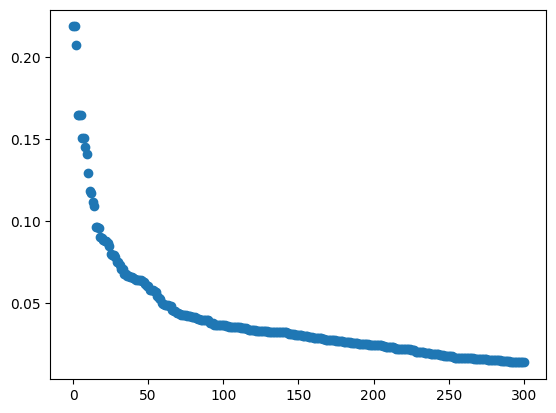

In [48]:
plt.scatter(range(301), J_global);

### PART 2 - Monday, November 21, 2022

In [ ]:
# Run algorithm for range of N, & plot best_fitness vs N (set vmax_coeff=0.1)
N = [10, 20, 30, 50]

### How does the number of particles affect the result of the PSO algorithm?

In [ ]:
# Run algorithm for range of vmax_coeff, the cutoff velocity coefficient (choose N according to experiment above)
vmax_coeff = [0, 0.1, 0.2, 0.3]

### How does the velocity cut-off $v_{max}$ affect the result of the PSO algorithm?

In [28]:
# Run algorithm 10 times, noting the prediction accuracy (or error) for each run 
# TODO

In [ ]:
# Plot the best_fitness of each run vs. the number of iterations it took (in case of stop condition #2)
# TODO

In [29]:
# For one of the 10 runs (choose the one with the best fitness), plot J(w1, w2) as a function of the iteration number
# TODO

### Comment on your results

Answer the following Questions: 

1.  Q: What is the Search Space of our problem?

    A: 


2.  Q: Explain the coefficients c1 & c2

    A:
    

3.  Q: How is PSO similar to Ant Algorithm?

    A:
